In [34]:
import numpy as np
import pandas as pd
import json

# Librerías de terceros
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.metrics import precision_score, recall_score, f1_score


In [35]:
df = pd.read_csv('../datasets/df_procesado.csv')
df.shape

(193050, 82)

In [37]:
df["issue_d"] = pd.to_datetime(df["issue_d"])

df = df.sort_values("issue_d").reset_index(drop=True)
n = len(df)
i_tr, i_va = int(n * 0.6), int(n * 0.8)

features = [c for c in df.columns if c not in ["loan_status", "issue_d"]]
X, y = df[features], df["loan_status"]

X_train, y_train = X.iloc[:i_tr],     y.iloc[:i_tr]
X_val,   y_val   = X.iloc[i_tr:i_va], y.iloc[i_tr:i_va]
X_test,  y_test  = X.iloc[i_va:],     y.iloc[i_va:]

# Para documentar en el informe: rango de fechas y tasa de default por partición
for nombre, parte in [("Train", df.iloc[:i_tr]), ("Val", df.iloc[i_tr:i_va]), ("Test", df.iloc[i_va:])]:
    print(f"{nombre}: {parte['issue_d'].min():%Y-%m} → {parte['issue_d'].max():%Y-%m} "
          f"| n={len(parte):,} | default={parte['loan_status'].mean():.3f}")

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

X_test_t = torch.tensor(X_test, dtype=torch.float32).to(device)

Train: 2012-08 → 2014-04 | n=115,830 | default=0.216
Val: 2014-04 → 2014-10 | n=38,610 | default=0.263
Test: 2014-10 → 2015-12 | n=38,610 | default=0.253


In [38]:
# 1. Ordenar el DataFrame cronológicamente por la fecha de originación
df = df.sort_values("issue_d").reset_index(drop=True)

# 2. Definir el punto de corte (ej: 80% más antiguo para entrenar, 20% más reciente para validar)
split_idx = int(len(df) * 0.8)

# 3. Separar X e Y (asegúrate de excluir 'issue_d' de las features ya que es un datetime)
features = [col for col in df.columns if col not in ["loan_status", "issue_d"]]

X = df[features]
y = df["loan_status"]

# 4. Partición temporal pura (sin mezclar ni estratificar)
X_train = X.iloc[:split_idx]
X_val = X.iloc[split_idx:]

y_train = y.iloc[:split_idx]
y_val = y.iloc[split_idx:]

# 5. Escalado estándar (ajustando únicamente con train para evitar fuga de datos)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

print(f"Train temporal: {X_train.shape} | Val temporal: {X_val.shape}")

Train temporal: (154440, 80) | Val temporal: (38610, 80)


In [39]:
print("Distribución de la variable respuesta en los datos de entrenamiento:")
print(y_train.value_counts(normalize=True))
print("\n")
print("Distribución de la variable respuesta en los datos de validación:")
print(y_val.value_counts(normalize=True))

Distribución de la variable respuesta en los datos de entrenamiento:
loan_status
0    0.771983
1    0.228017
Name: proportion, dtype: float64


Distribución de la variable respuesta en los datos de validación:
loan_status
0    0.746957
1    0.253043
Name: proportion, dtype: float64


In [40]:
# Selecciona GPU si está disponible, de lo contrario usa CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Muestra el dispositivo que se está utilizando
print(f"Usando: {device}")

Usando: cpu


In [41]:

# Convertir a tensores y crear DataLoaders
X_train_t = torch.tensor(X_train, dtype=torch.float32).to(device)
X_val_t  = torch.tensor(X_val,  dtype=torch.float32).to(device)
y_train_t = torch.tensor(y_train.to_numpy(), dtype=torch.float32).to(device)
y_val_t  = torch.tensor(y_val.to_numpy(),  dtype=torch.float32).to(device)

train_ds = TensorDataset(X_train_t, y_train_t)
test_ds  = TensorDataset(X_val_t,  y_val_t)

train_loader = DataLoader(train_ds, batch_size=512, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=512, shuffle=False)

print(f"Batches en train: {len(train_loader)}")

Batches en train: 302


In [42]:
# Definir arquitectura de la red neuronal
# Estructura: Input → 128 → 64 → 32 → 1
# Dropout para regularización, BatchNorm para estabilidad

class CreditRiskNN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            # Capa 1
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),
            # Capa 2
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.2),
            # Capa 3
            nn.Linear(32, 16),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            #nn.Dropout(0.2),
            # Salida — probabilidad de default
            nn.Linear(16, 1),
            #nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x).squeeze(1)

model = CreditRiskNN(input_dim=X_train.shape[1]).to(device)
print(model)
print(f"\nParámetros totales: {sum(p.numel() for p in model.parameters()):,}")

CreditRiskNN(
  (network): Sequential(
    (0): Linear(in_features=80, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Linear(in_features=16, out_features=1, bias=True)
  )
)

Parámetros totales: 8,033


In [43]:
# Configurar entrenamiento
# BCELoss con pos_weight para manejar desbalance de clases

# Peso para clase positiva (default) según desbalance
n_neg = (y_train == 0).sum()
n_pos = (y_train == 1).sum()
pos_weight = torch.tensor([n_neg / n_pos], dtype=torch.float32).to(device)
print(f"pos_weight: {pos_weight.item():.2f}  (negativos/positivos)")

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", patience=3, factor=0.5
)

pos_weight: 3.39  (negativos/positivos)


In [44]:
import torch

# Loop de entrenamiento

EPOCHS = 30
history = {"train_loss": [], "val_auc": []}

patience = 10
patience_counter = 0 
best_val_auc = 0.0  

for epoch in range(1, EPOCHS + 1):
  model.train()
  total_loss = 0
  for X_batch, y_batch in train_loader:
    optimizer.zero_grad()
    preds = model(X_batch)
    loss = criterion(preds, y_batch)
    loss.backward()
    optimizer.step()
    total_loss += loss.item()

  avg_loss = total_loss / len(train_loader)

  model.eval()
  with torch.no_grad():
    y_prob_val = model(X_val_t).cpu().numpy()

  val_auc = roc_auc_score(y_val, y_prob_val)
  scheduler.step(val_auc)
  print(f"Epoch {epoch} | LR: {optimizer.param_groups[0]['lr']}")

  history["train_loss"].append(avg_loss)
  history["val_auc"].append(val_auc)

  if epoch % 5 == 0 or epoch == 1:
    print(
        f"Epoch {epoch:02d}/{EPOCHS} | Loss: {avg_loss:.4f} | AUC:"
        f" {val_auc:.4f}"
    )

  if val_auc > best_val_auc: 
    best_val_auc = val_auc  
    patience_counter = 0  
    torch.save(
        model.state_dict(), "best_model.pth"
    )  
  else:
    patience_counter += 1 
    if patience_counter >= patience:  
      print(
          f"Early stopping activado en la época {epoch}. Deteniendo"
          " entrenamiento."
      )
      break  

model.load_state_dict(
    torch.load("best_model.pth")
)  
model.eval()
with torch.no_grad():
  y_prob = (
      model(X_val_t).cpu().numpy()
  )  

Epoch 1 | LR: 0.001
Epoch 01/30 | Loss: 1.0002 | AUC: 0.7047
Epoch 2 | LR: 0.001
Epoch 3 | LR: 0.001
Epoch 4 | LR: 0.001
Epoch 5 | LR: 0.001
Epoch 05/30 | Loss: 0.9696 | AUC: 0.7061
Epoch 6 | LR: 0.0005
Epoch 7 | LR: 0.0005
Epoch 8 | LR: 0.0005
Epoch 9 | LR: 0.0005
Epoch 10 | LR: 0.0005
Epoch 10/30 | Loss: 0.9643 | AUC: 0.7086
Epoch 11 | LR: 0.0005
Epoch 12 | LR: 0.0005
Epoch 13 | LR: 0.0005
Epoch 14 | LR: 0.00025
Epoch 15 | LR: 0.00025
Epoch 15/30 | Loss: 0.9606 | AUC: 0.7104
Epoch 16 | LR: 0.00025
Epoch 17 | LR: 0.00025
Epoch 18 | LR: 0.00025
Epoch 19 | LR: 0.000125
Epoch 20 | LR: 0.000125
Epoch 20/30 | Loss: 0.9581 | AUC: 0.7083
Epoch 21 | LR: 0.000125
Epoch 22 | LR: 0.000125
Epoch 23 | LR: 6.25e-05
Epoch 24 | LR: 6.25e-05
Epoch 25 | LR: 6.25e-05
Epoch 25/30 | Loss: 0.9578 | AUC: 0.7090
Early stopping activado en la época 25. Deteniendo entrenamiento.


In [45]:
from scipy.stats import ks_2samp
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve

def predecir_proba(model, X_t, pos_weight):
    model.eval()
    with torch.no_grad():
        logits = model(X_t) - torch.log(pos_weight)   # deshace el efecto de pos_weight
        return torch.sigmoid(logits).cpu().numpy()

def evaluar(y_true, p, nombre):
    auc = roc_auc_score(y_true, p)
    return {
        "Conjunto": nombre,
        "AUC": auc,
        "Gini": 2 * auc - 1,
        "KS": ks_2samp(p[y_true == 1], p[y_true == 0]).statistic,
        "Brier": brier_score_loss(y_true, p),
        "Brier referencia": y_true.mean() * (1 - y_true.mean()),  # modelo que predice la tasa base
    }

y_val_np, y_test_np = y_val.to_numpy(), y_test.to_numpy()
p_val  = predecir_proba(model, X_val_t,  pos_weight)
p_test = predecir_proba(model, X_test_t, pos_weight)

print(pd.DataFrame([evaluar(y_val_np, p_val, "Validación"),
                    evaluar(y_test_np, p_test, "Test")]).round(4).to_string(index=False))

  Conjunto    AUC   Gini     KS  Brier  Brier referencia
Validación 0.7104 0.4209 0.3120 0.1726            0.1890
      Test 0.7105 0.4210 0.3117 0.1725            0.1891


In [46]:
thresholds = np.linspace(0.01, 0.9, 100)

results = []

for t in thresholds:
    y_pred_val = (p_val > t).astype(int)          # <- p_val, no y_prob_val
    results.append((
        t,
        precision_score(y_val_np, y_pred_val, zero_division=0),
        recall_score(y_val_np, y_pred_val),
        f1_score(y_val_np, y_pred_val),
    ))

results = np.array(results)

In [47]:
# encontrar mejor threshold según F1
best_idx = np.argmax(results[:, 3])
best_threshold = results[best_idx, 0]
best_precision = results[best_idx, 1]
best_recall = results[best_idx, 2]
best_f1 = results[best_idx, 3]  
print(f"Mejor threshold: {best_threshold:.2f} | Precision: {best_precision:.4f} | Recall: {best_recall:.4f} | F1: {best_f1:.4f}")
    

Mejor threshold: 0.18 | Precision: 0.3726 | Recall: 0.7208 | F1: 0.4913


In [48]:
# Después del loop de entrenamiento
model.eval()
with torch.no_grad():
    logits = model(X_val_t)
    y_prob_val = torch.sigmoid(logits).cpu().numpy().flatten()
    y_pred = (y_prob_val > best_threshold).astype(int)

classification_report(y_val, y_pred)

'              precision    recall  f1-score   support\n\n           0       0.96      0.09      0.16     28840\n           1       0.27      0.99      0.42      9770\n\n    accuracy                           0.32     38610\n   macro avg       0.61      0.54      0.29     38610\nweighted avg       0.78      0.32      0.23     38610\n'

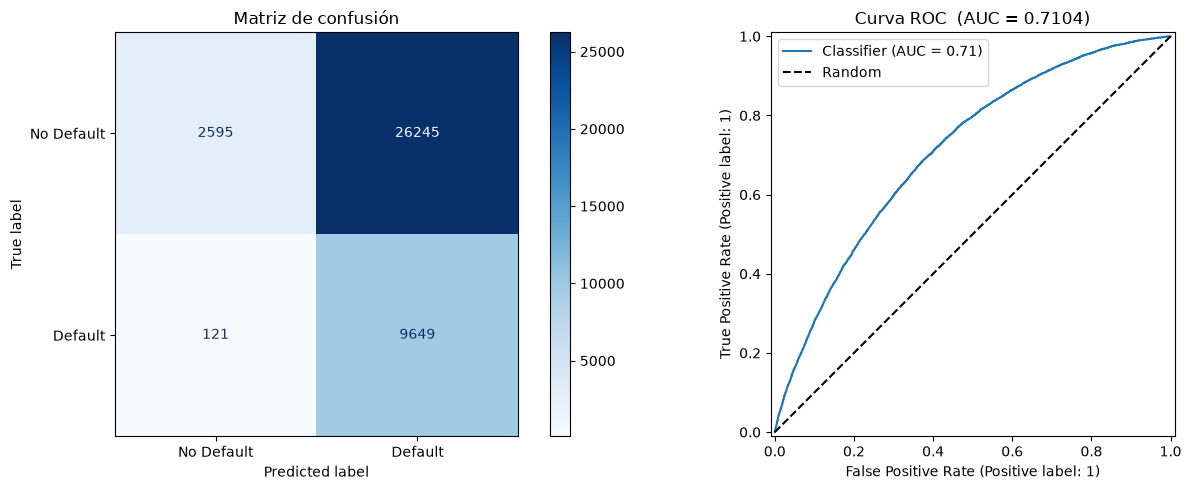

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred,
    display_labels=["No Default", "Default"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Matriz de confusión")

# Curva ROC
RocCurveDisplay.from_predictions(y_val, y_prob_val, ax=axes[1])
axes[1].set_title(f"Curva ROC  (AUC = {roc_auc_score(y_val, y_prob_val):.4f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Random")
axes[1].legend()

plt.tight_layout()
plt.show()


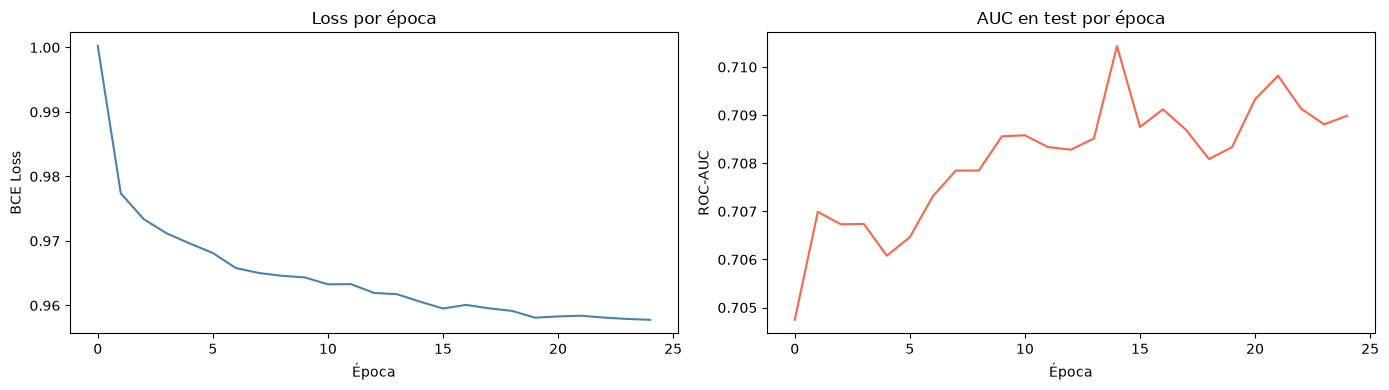

In [50]:

# Curvas de entrenamiento
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(history["train_loss"], color="steelblue")
axes[0].set_title("Loss por época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("BCE Loss")

axes[1].plot(history["val_auc"], color="tomato")
axes[1].set_title("AUC en test por época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("ROC-AUC")

plt.tight_layout()
plt.show()

In [51]:
model.eval()
with torch.no_grad():
    y_prob = model(X_val_t).cpu().numpy()

y_pred = (y_prob >= 0.5).astype(int)

print("── Classification Report ──────────────────────────────────")
print(classification_report(y_val, y_pred,
                             target_names=["No Default", "Default"]))
print(f"ROC-AUC: {roc_auc_score(y_val, y_prob):.4f}")

── Classification Report ──────────────────────────────────
              precision    recall  f1-score   support

  No Default       0.79      0.87      0.83     28840
     Default       0.47      0.33      0.39      9770

    accuracy                           0.74     38610
   macro avg       0.63      0.60      0.61     38610
weighted avg       0.71      0.74      0.72     38610

ROC-AUC: 0.7104


In [52]:

# import pickle

torch.save(model.state_dict(), "../weights/modelo_clasificador.pth")
# pickle.dump(scaler, open("scaler.pkl", "wb"))

print("Modelo guardado en modelo_clasificador.pth")
print("Scaler guardado en scaler.pkl")

Modelo guardado en modelo_clasificador.pth
Scaler guardado en scaler.pkl


In [53]:
from scipy.stats import ks_2samp
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve

def predecir_proba(model, X_t, pos_weight):
    model.eval()
    with torch.no_grad():
        logits = model(X_t) - torch.log(pos_weight)   # deshace el efecto de pos_weight
        return torch.sigmoid(logits).cpu().numpy()

def evaluar(y_true, p, nombre):
    auc = roc_auc_score(y_true, p)
    return {
        "Conjunto": nombre,
        "AUC": auc,
        "Gini": 2 * auc - 1,
        "KS": ks_2samp(p[y_true == 1], p[y_true == 0]).statistic,
        "Brier": brier_score_loss(y_true, p),
        "Brier referencia": y_true.mean() * (1 - y_true.mean()),  # modelo que predice la tasa base
    }

y_val_np, y_test_np = y_val.to_numpy(), y_test.to_numpy()
p_val  = predecir_proba(model, X_val_t,  pos_weight)
p_test = predecir_proba(model, X_test_t, pos_weight)

print(pd.DataFrame([evaluar(y_val_np, p_val, "Validación"),
                    evaluar(y_test_np, p_test, "Test")]).round(4).to_string(index=False))

  Conjunto    AUC   Gini     KS  Brier  Brier referencia
Validación 0.7104 0.4209 0.3120 0.1726            0.1890
      Test 0.7105 0.4210 0.3117 0.1725            0.1891


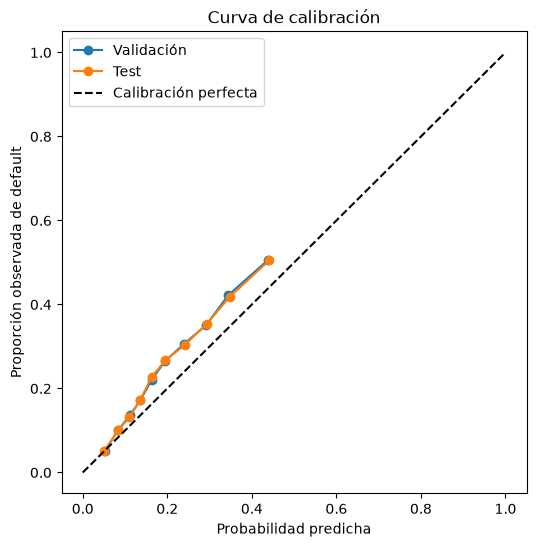

In [54]:
fig, ax = plt.subplots(figsize=(6, 6))
for nombre, yt, p in [("Validación", y_val_np, p_val), ("Test", y_test_np, p_test)]:
    frac_pos, prob_media = calibration_curve(yt, p, n_bins=10, strategy="quantile")
    ax.plot(prob_media, frac_pos, "o-", label=nombre)
ax.plot([0, 1], [0, 1], "k--", label="Calibración perfecta")
ax.set_xlabel("Probabilidad predicha")
ax.set_ylabel("Proporción observada de default")
ax.set_title("Curva de calibración")
ax.legend()
plt.show()